<a href="https://colab.research.google.com/github/P-shettar/ML-LAB-02/blob/main/program_7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Dataset downloaded successfully!
Dataset Shape: (1627, 29)

Selected Dataset Shape: (1627, 15)
Data standardization completed!


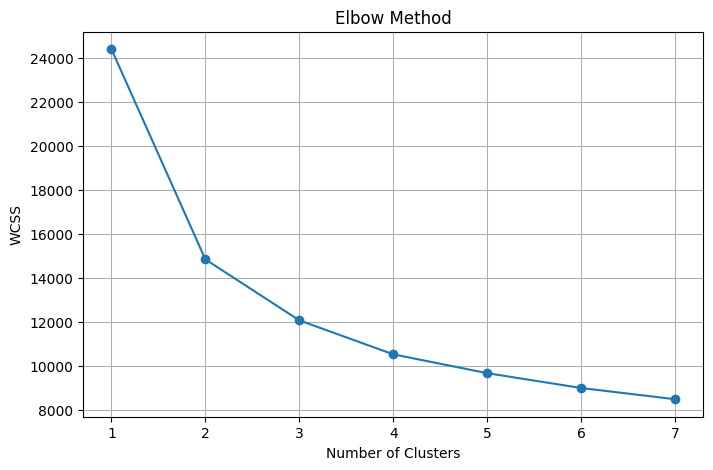


Clustered Dataset:
      age  height_cm  weight_kg  potential  attacking_crossing  \
816    23        177         73         76                  57   
1167   24        186         82         68                   9   
1434   20        187         82         68                  54   
1220   19        180         70         75                  63   
303    29        188         77         58                  10   
1055   24        188         85         70                  48   
710    30        184         78         69                  71   
901    20        187         85         76                  58   
1532   18        171         67         76                  50   
65     34        178         70         69                  71   

      attacking_finishing  attacking_short_passing  skill_dribbling  \
816                    64                       57               73   
1167                    6                       39                7   
1434                   35               

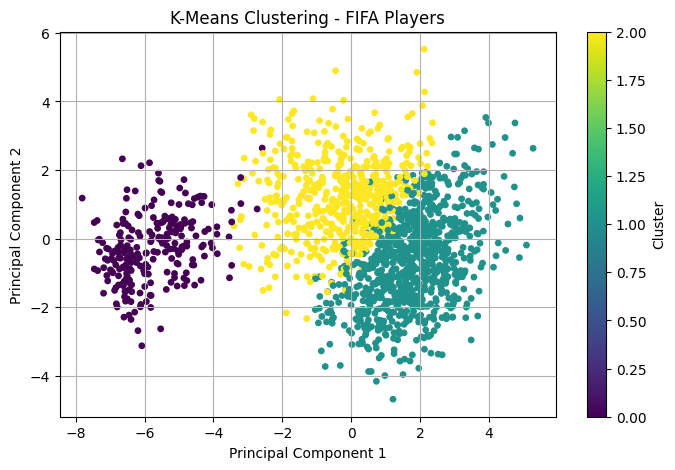


K-Means Clustering Completed Successfully!


In [1]:

# EXPERIMENT 7: K-MEANS CLUSTERING

# Step 1: Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

# Step 2: Download dataset
url = "https://people.stat.sc.edu/gregorkb/data/fifa_usge.csv"

df = pd.read_csv(url)

print("Dataset downloaded successfully!")
print("Dataset Shape:", df.shape)

# Step 3: Select numerical features
features = [
    "age",
    "height_cm",
    "weight_kg",
    "potential",
    "attacking_crossing",
    "attacking_finishing",
    "attacking_short_passing",
    "skill_dribbling",
    "skill_ball_control",
    "movement_acceleration",
    "movement_sprint_speed",
    "movement_agility",
    "movement_reactions",
    "defending_standing_tackle",
    "defending_sliding_tackle"
]

features = [f for f in features if f in df.columns]

# Remove missing values
df = df.dropna(subset=features).copy()

X = df[features]

# Use 5000 samples for faster execution
X = X.sample(
    n=min(5000, len(X)),
    random_state=42
)

print("\nSelected Dataset Shape:", X.shape)

# Step 4: Standardize data
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Data standardization completed!")

# Step 5: Elbow Method
wcss = []

for k in range(1, 8):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=5
    )

    kmeans.fit(X_scaled)

    wcss.append(kmeans.inertia_)

# Step 6: Plot Elbow graph
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, 8),
    wcss,
    marker="o"
)

plt.title("Elbow Method")
plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")
plt.grid()
plt.show()

# Step 7: Apply K-Means
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=5
)

clusters = kmeans.fit_predict(X_scaled)

# Step 8: Add cluster labels
X = X.copy()
X["Cluster"] = clusters

print("\nClustered Dataset:")
print(X.head(10))

# Step 9: Display cluster distribution
print("\nCluster Distribution:")
print(X["Cluster"].value_counts().sort_index())

# Step 10: Silhouette Score
score = silhouette_score(
    X_scaled,
    clusters
)

print("\nSilhouette Score:", score)

# Step 11: PCA visualization
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(8, 5))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=clusters,
    cmap="viridis",
    s=15
)

plt.title("K-Means Clustering - FIFA Players")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.colorbar(label="Cluster")
plt.grid()
plt.show()

print("\nK-Means Clustering Completed Successfully!")
